<a href="https://colab.research.google.com/github/Duman18/portfolio-risk-engine/blob/main/01_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
tickers = ["0005.HK", "0700.HK", "1299.HK", "0388.HK", "2800.HK"]

prices = yf.download(tickers, start="2015-01-01", end="2026-01-01",
                     auto_adjust=True)["Close"]

prices.head()

[*********************100%***********************]  5 of 5 completed


Ticker,0005.HK,0388.HK,0700.HK,1299.HK,2800.HK
Date,,,,,
2015-01-02,38.590515,126.428955,97.894012,35.109886,16.502010
2015-01-05,38.016876,129.571381,98.501518,34.470810,16.433397
2015-01-06,37.417152,129.790665,104.142555,33.552116,16.227551
2015-01-07,37.026028,131.032959,107.961121,33.592064,16.399086
2015-01-08,37.130341,129.936798,110.477890,34.111313,16.536318


In [8]:
print(prices.shape)
print(prices.isna().sum())

(2708, 5)
Ticker
0005.HK    0
0388.HK    0
0700.HK    0
1299.HK    0
2800.HK    0
dtype: int64


In [4]:
prices = prices.dropna()

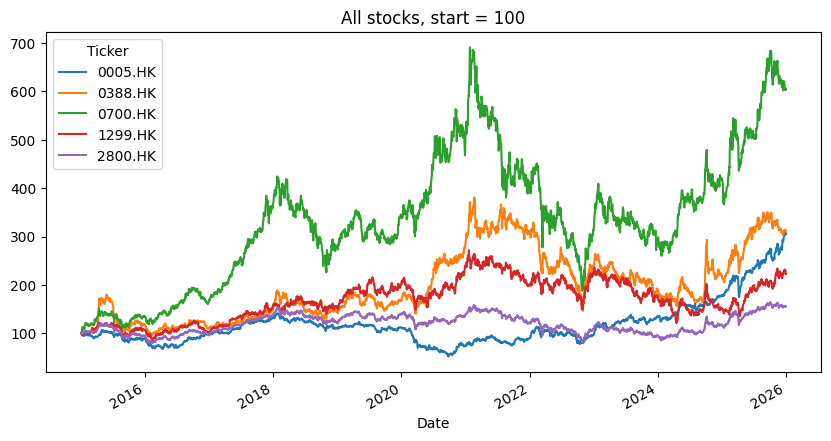

In [5]:
(prices / prices.iloc[0] * 100).plot(figsize=(10,5), title="All stocks, start = 100")
plt.show()

In [6]:
returns = prices.pct_change().dropna()
returns.head()

Ticker,0005.HK,0388.HK,0700.HK,1299.HK,2800.HK
Date,,,,,
2015-01-05,-0.014865,0.024855,0.006206,-0.018202,-0.004158
2015-01-06,-0.015775,0.001692,0.057269,-0.026651,-0.012526
2015-01-07,-0.010453,0.009572,0.036667,0.001191,0.010571
2015-01-08,0.002817,-0.008366,0.023312,0.015457,0.008368
2015-01-09,-0.001405,-0.004500,-0.000785,0.005855,0.004150


In [7]:
returns.describe()

Ticker,0005.HK,0388.HK,0700.HK,1299.HK,2800.HK
count,2707.000000,2707.000000,2707.000000,2707.000000,2707.000000
mean,0.000517,0.000621,0.000906,0.000466,0.000257
std,0.014483,0.020130,0.022008,0.018478,0.013735
min,-0.147503,-0.142610,-0.125352,-0.114837,-0.133967
25%,-0.006256,-0.009923,-0.011083,-0.009930,-0.007246
50%,0.000541,-0.000519,0.000000,0.000000,0.000000
75%,0.007474,0.009608,0.012164,0.010489,0.007649
max,0.092198,0.192771,0.231544,0.087863,0.085254


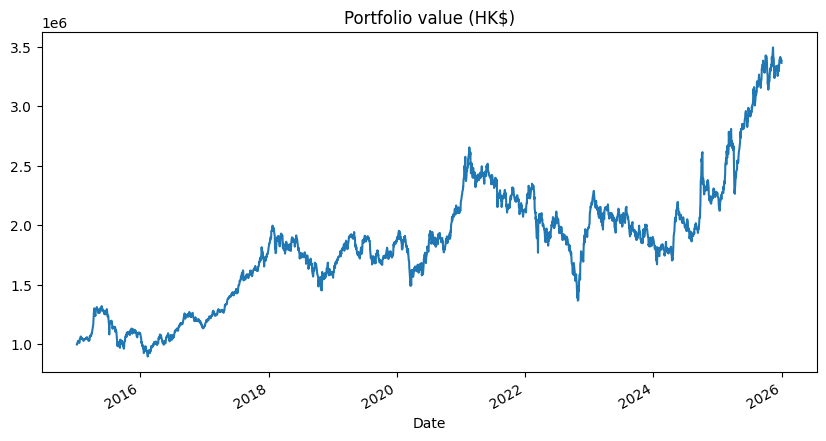

In [9]:
weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
port_returns = returns.dot(weights)

port_value = 1_000_000 * (1 + port_returns).cumprod()

port_value.plot(figsize=(10,5), title="Portfolio value (HK$)")
plt.show()

In [10]:
summary = pd.DataFrame({
    "Avg daily return": returns.mean(),
    "Daily volatility": returns.std(),
    "Yearly volatility": returns.std() * np.sqrt(252)
})
print(summary)

print(returns.corr().round(2))

         Avg daily return  Daily volatility  Yearly volatility
Ticker                                                        
0005.HK          0.000517          0.014483           0.229914
0388.HK          0.000621          0.020130           0.319559
0700.HK          0.000906          0.022008           0.349363
1299.HK          0.000466          0.018478           0.293327
2800.HK          0.000257          0.013735           0.218041
Ticker   0005.HK  0388.HK  0700.HK  1299.HK  2800.HK
Ticker                                              
0005.HK     1.00     0.38     0.33     0.48     0.58
0388.HK     0.38     1.00     0.66     0.59     0.79
0700.HK     0.33     0.66     1.00     0.50     0.77
1299.HK     0.48     0.59     0.50     1.00     0.73
2800.HK     0.58     0.79     0.77     0.73     1.00


In [11]:
print("Portfolio daily volatility:", port_returns.std())

Portfolio daily volatility: 0.014489838285142904


In [12]:
prices.to_csv("prices.csv")
returns.to_csv("returns.csv")

from google.colab import files
files.download("prices.csv")
files.download("returns.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>